| **Name** | **Family Name** | **Matriculation Number** |
| -------- | --------------- | ------------------------ |
| Marco    | Lorenzato       | 2197529                  |
| Kevin    | Brugnera        | 2196578                  |
| Nicolò   | Teneggi         | 2195476                  |
| Polina   | Gridiaeva       | 2186171                  |

# Convolutional Neural Network, CNN

Similarly to the lesson, introduce a pattern that affects both time series around the same position in the sample. For example, one can introduce a “sin”-like bump in series 1 followed by another one in series 2. 
The number of categories can also be increased depending on the chosen combinations. 
Describe your choice at the beginning of the jupyter.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 14

import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten #, Reshape
from keras.layers import Conv1D, MaxPooling1D, AveragePooling1D
import tensorflow.random as tf_r

import pandas as pd
from scipy import stats
import seaborn 
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn import preprocessing


# reproducibility
np.random.seed(12345)
tf_r.set_seed(12345)

%run plot.py

## 2. Variation of the Amplitude (A)

Study the performance of the CNN by varying the amplitude A of the patterns while keeping DX fixed, namely by changing the signal-to-noise ratio. 

In [2]:
def create_model(NCONV = 1):
    ## from keras import regularizers, initializers

    reg = tf.keras.regularizers.l2(0.2) ## raised to 0.2 the regularization strenghts
    #reg = regularizers.l1(0.1)
    ini = tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.05, 
                                            seed=None)
    NF = 5 #number of filters

    # challenge: at most 600 tunable parameters
    model = Sequential()
    # 
    if NCONV==1:
        # -----2-----
        model.add(Conv1D(filters=NF, kernel_size=11, 
                         kernel_initializer=ini, 
                         kernel_regularizer=reg,
                         activation='relu', 
                         input_shape=input_shape))
        #model.add(MaxPooling1D(3))
        model.add(AveragePooling1D(5))
        model.add(Conv1D(filters=5, kernel_size=7, 
                         activation='relu'))
        model.add(Flatten())
        model.add(Dense(12, activation='relu'))
        model.add(Dropout(0.2))
    # 
    if NCONV==2:
        # -----1-----
        model.add(Conv1D(filters=NF, kernel_size=11, 
                         kernel_initializer=ini, 
                         kernel_regularizer=reg, ######## TRY WITHOUT !
                         activation='relu', input_shape=input_shape))
        #model.add(MaxPooling1D(3))
        model.add(AveragePooling1D(5))
        model.add(Flatten())
        model.add(Dense(9, activation='relu'))
        model.add(Dropout(0.2))
        model.add(Dense(6, activation='relu'))
        model.add(Dropout(0.2))
        #model.add(Dense(10, activation='relu'))
        #model.add(Dropout(0.3))
    model.add(Dense(n_class, activation='softmax')) # softmax !

    #print('----- Model',NCONV,'-----')
    #print(model.summary())

    # optimizers
    # .SGD(lr=0.01, momentum=0.9, nesterov=True) # decay=1e-6,
    # .RMSprop()
    # .Nadam()
    opt = tf.keras.optimizers.Adam()

    # compile the model
    # categorical_crossentropy, 3 output nodes
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer=opt,metrics=['accuracy'])
    return model

In [3]:
def Show_history(fit):
    fig,AX=plt.subplots(1,2,figsize=(12,5.))
    ax=AX[0] 
    ax.plot(fit.history['accuracy'],"b",label="train")
    ax.plot(fit.history['val_accuracy'],"r--",label="valid.")
    ax.plot((0,EPOCHS),(1/3,1/3),":",c="gray",label="random choice")
    ax.set_xlabel('epoch')
    ax.set_ylabel("Accuracy")
    ax.set_ylim([0, 1])
    ax.legend()
    ax=AX[1]
    ax.plot(fit.history['loss'],"b",label="train")
    ax.plot(fit.history['val_loss'],"r--",label="valid.")
    ax.set_xlabel('epoch')
    ax.set_ylabel("Loss")
    ax.set_ylim([0, 1.05*np.max(fit.history['loss'])])
    ax.legend()
    plt.show()

In [4]:
LABELS = ["absent","positive","negative"] # from labels y 
cmap="GnBu"

def show_confusion_matrix(validations, predictions, label="Model"):

    matrix = metrics.confusion_matrix(validations, predictions)
    plt.figure(figsize=(6, 5))
    seaborn.heatmap(matrix,
                xticklabels=LABELS,
                yticklabels=LABELS,
                annot=True,
                fmt='d',
                linecolor='white',
                linewidths=1,
                cmap=cmap)
    plt.title(label+': Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

Considering the same dataset generation procedure used during the lecture, we fixed different values of the amplitude with which the model was trained. In particular, we selected $ A \in [200, 500, 1000, 2000] $.

Below we show the plot of some features obtained from each dataset.

In [6]:
list_A = [200, 500, 1000, 2000]
x_list, y_list = [], []

for A in list_A:
    str0 = f'ts_L60_Z12_A{A}_DX50_bias5_N10000.dat'

    fnamex='DATA/x_'+str0
    fnamey='DATA/y_'+str0

    x = np.loadtxt(fnamex, delimiter=" ",dtype=float)
    x_list.append(x)
    # number of samples, number of features
    N,L = len(x), len(x[0])
 
    #Show_data(x,L,f"Original data, A = {A}")
    print(f'A = {A} with N:= {N} samples' )

    categ = np.loadtxt(fnamey, dtype=int)
    n_class = 3    # y.argmax() - y.argmin() +1

    y = np.zeros((N,n_class))
    for i in range(N):
        y[i][categ[i]] = 1. # y contains one-hot encoding
    y_list.append(y)

A = 200 with N:= 10000 samples
A = 500 with N:= 10000 samples
A = 1000 with N:= 10000 samples
A = 2000 with N:= 10000 samples


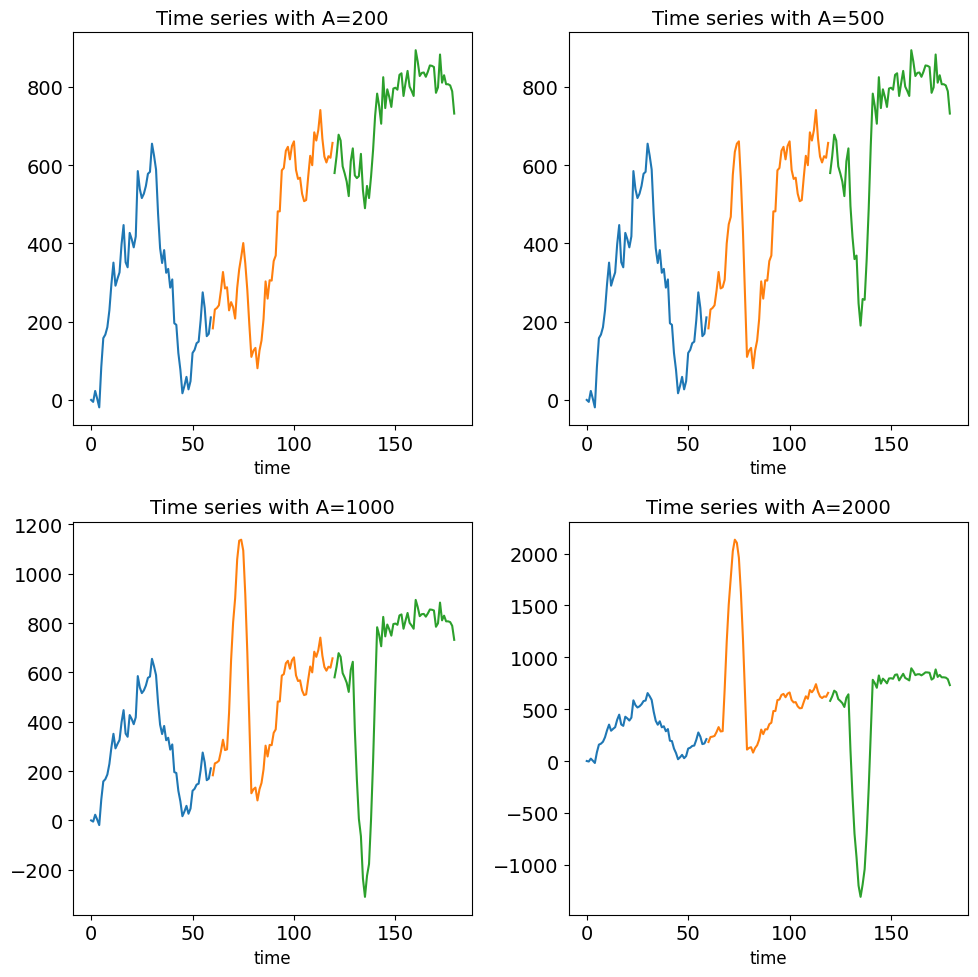

In [7]:
def Show_data(x,L,s="data"):
    plt.plot(np.arange(L),x[0])
    plt.plot(np.arange(L,2*L),x[1])
    plt.plot(np.arange(2*L,3*L),x[2])
    plt.title(s, fontsize=14)
    plt.xlabel("time", fontsize=12)

plt.figure(figsize=(10, 10))
plt.subplot(221)
Show_data(x_list[0],L, f'Time series with A={list_A[0]}')
plt.subplot(222)
Show_data(x_list[1],L, f'Time series with A={list_A[1]}')
plt.subplot(223)
Show_data(x_list[2],L, f'Time series with A={list_A[2]}')
plt.subplot(224)
Show_data(x_list[3],L, f'Time series with A={list_A[3]}')
plt.tight_layout()
plt.show()

Once the dataset was generated, we proceeded with training the model. In particular, we chose to train the model with $ \text{NCONV} = 1 $.

(8000, 60)
N_train= 8000   N_val= 2000   L= 60   n_class= 3
std_train average and mean: 3.394586101911389 0.26281290363285187 1.0
std_val average and mean: 3.1605916503149483 0.32081713140999235 0.9999999999999999


/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


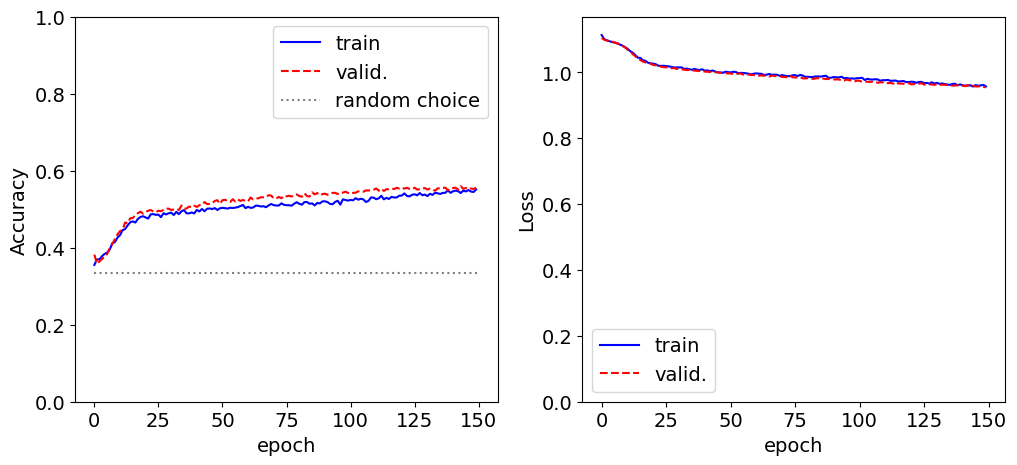

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


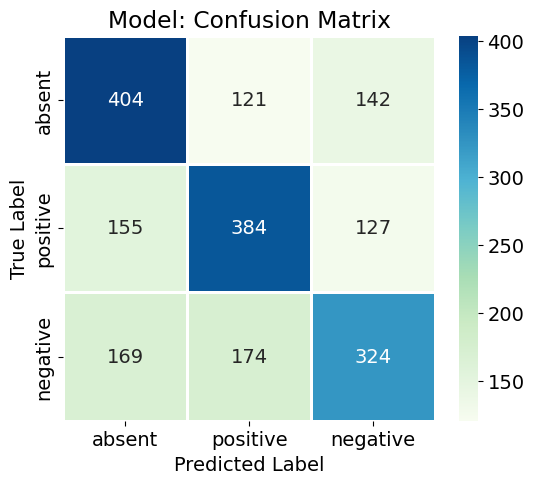

(8000, 60)
N_train= 8000   N_val= 2000   L= 60   n_class= 3
std_train average and mean: 2.919858910144656 0.22258218470654462 1.0
std_val average and mean: 2.822424783755405 0.27271535791982854 0.9999999999999998


/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


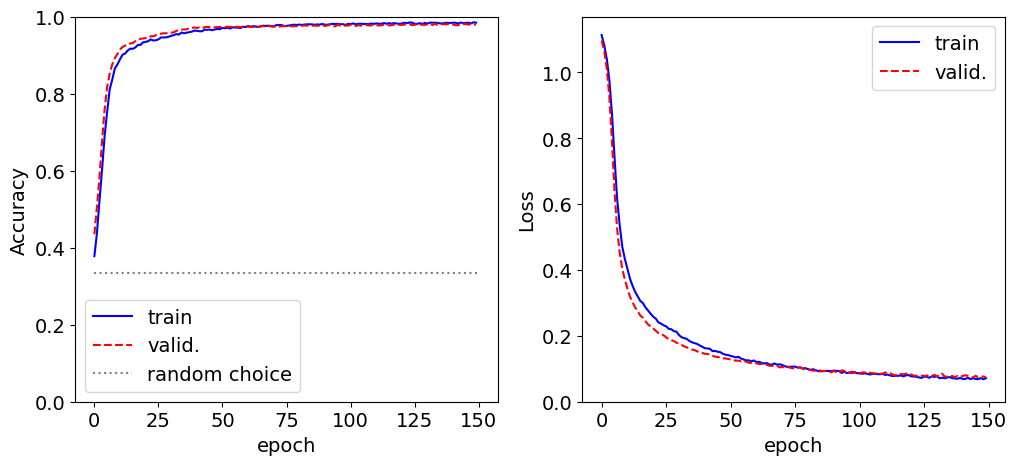

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


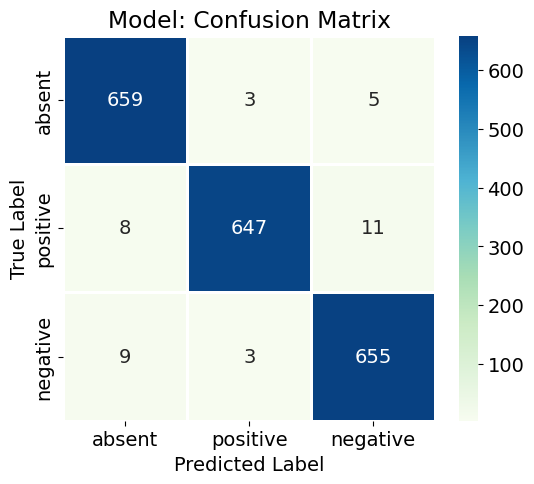

(8000, 60)
N_train= 8000   N_val= 2000   L= 60   n_class= 3
std_train average and mean: 2.464209031444881 0.1614186672598757 1.0
std_val average and mean: 2.4193213759968244 0.198220447377455 1.0


/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


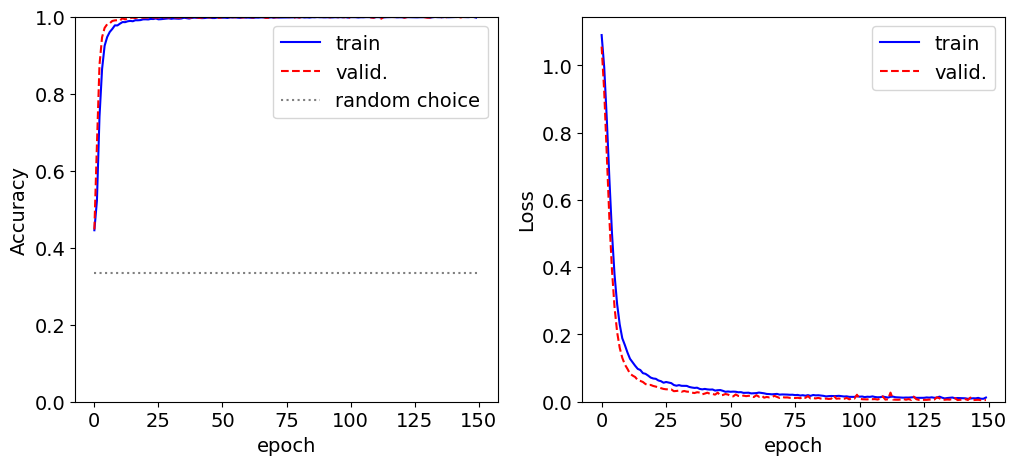

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


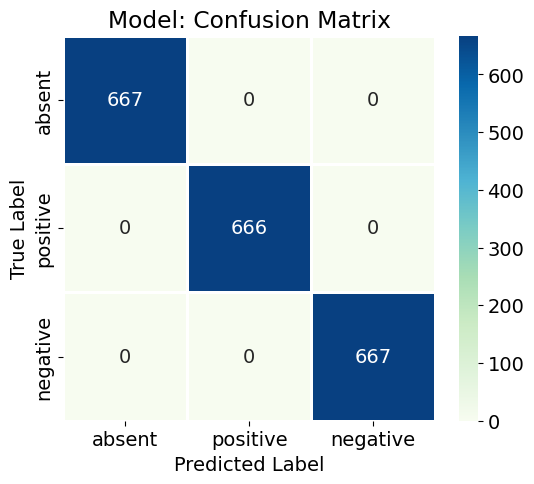

(8000, 60)
N_train= 8000   N_val= 2000   L= 60   n_class= 3
std_train average and mean: 2.034123026232298 0.09811751035147781 0.9999999999999999
std_val average and mean: 1.9962831972228943 0.12055227389552446 1.0


/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


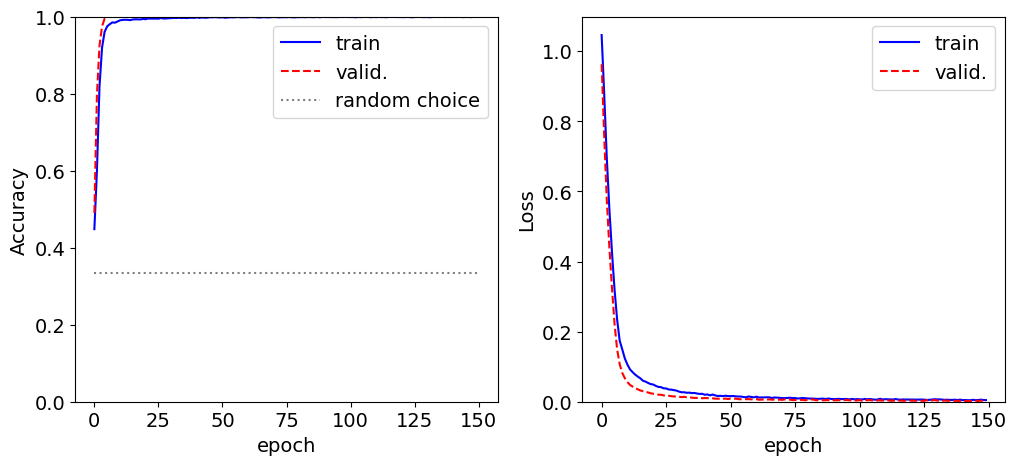

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


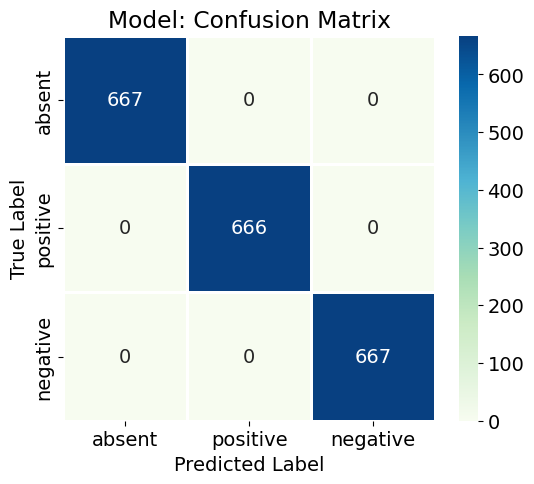

In [38]:
for x, y in zip(x_list, y_list):

    # split into training and validation sets
    perc_train=0.8
    N_train = int(perc_train*N)
    x_train = x[:N_train]
    print(x_train.shape)
    y_train = y[:N_train]
    x_val = x[N_train:]
    y_val = y[N_train:]
    N_val = len(x_val)
    print('N_train=',N_train,'  N_val=',N_val,'  L=',L,'  n_class=',n_class)

    #remove average value of each sample from its values
    xm_train = x_train.mean(axis=1)
    std_train = x_train.std(axis=1)
    xm_val = x_val.mean(axis=1)
    std_val = x_val.std(axis=1)
    print('std_train average and mean:',max(std_train), min(std_train), std_train.mean(axis=0))
    print('std_val average and mean:',max(std_val), min(std_val), std_val.mean(axis=0))

    # rescale with variance on the training set
    for i in range(N_train):
        x_train[i] = (x_train[i]-xm_train[i])/ std_train.mean(axis=0)
    for i in range(N_val):
        x_val[i] = (x_val[i]-xm_val[i])/ std_val.mean(axis=0)
    
    #Show_data(x_train,L,f"rescaled train data, A = {A}")
    #Show_data(x_val,L,f"rescaled validation data, A = {A}")

    # Keras wants an additional dimension with a 1 at the end
    x_train = x_train.reshape(x_train.shape[0], L, 1)
    x_val =  x_val.reshape(x_val.shape[0], L, 1)
    input_shape = (L, 1) # number of features, number of channels (1 for 1D data)

    # with small minibatch it does not converge!! 
    BATCH_SIZE = 200
    EPOCHS = 150
    
    model = create_model(NCONV=1)
    #print('----- Model ',NCONV,'-----\nFITTING....')
    fit = model.fit(x_train,y_train,batch_size=BATCH_SIZE,
                    epochs=EPOCHS,
                    validation_data=(x_val, y_val),
                    verbose=0, shuffle=True) 
    Show_history(fit)

    y_pred_val = model.predict(x_val)
    max_y_pred_val = np.argmax(y_pred_val, axis=1)
    max_y_val = np.argmax(y_val, axis=1)

    show_confusion_matrix(max_y_val, max_y_pred_val)

We observe that the performance improves for higher values of the amplitude, reaching a perfect prediction on the validation set for $A = 2000$. This behavior can be explained by the fact that larger amplitudes produce more pronounced sinusoidal jumps in the time series, as shown in the dataset plots above. As a consequence, the patterns become significantly easier to distinguish and classify according to their true labels.

## 3. Regularization 

Check if regularization may improve the performances by varying the parameter lambda (as usual in magnitude: $ 0, 10^{-5}, 10^{-4}, 10^{-3} $, etc.) of the L1 (LASSO) or of the L2 (Ridge) regularization; see lambda in eqs.(43) and (52) in the review. There is also a mixed version (l1_l2) that can be tried. 

In [13]:
lambda_list = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1] 

To perform the training with regularization, we used the training set generated during the lecture.

In [11]:
str0 = 'ts_L60_Z12_A500_DX50_bias5_N10000.dat'
fnamex='DATA/x_'+str0
fnamey='DATA/y_'+str0
x = np.loadtxt(fnamex, delimiter=" ",dtype=float)
categ = np.loadtxt(fnamey, dtype=int)
n_class = 3  
y = np.zeros((N,n_class))
for i in range(N):
    y[i][categ[i]] = 1. # y contains one-hot encoding

# split into training and validation sets
perc_train=0.8
N_train = int(perc_train*N)
x_train = x[:N_train]
print(x_train.shape)
y_train = y[:N_train]
x_val = x[N_train:]
y_val = y[N_train:]
N_val = len(x_val)
print('N_train=',N_train,'  N_val=',N_val,'  L=',L,'  n_class=',n_class)

#remove average value of each sample from its values
xm_train = x_train.mean(axis=1)
std_train = x_train.std(axis=1)
xm_val = x_val.mean(axis=1)
std_val = x_val.std(axis=1)
print('std_train average and mean:',max(std_train), min(std_train), std_train.mean(axis=0))
print('std_val average and mean:',max(std_val), min(std_val), std_val.mean(axis=0))

# rescale with variance on the training set
for i in range(N_train):
     x_train[i] = (x_train[i]-xm_train[i])/ std_train.mean(axis=0)
for i in range(N_val):
    x_val[i] = (x_val[i]-xm_val[i])/ std_val.mean(axis=0)

# Keras wants an additional dimension with a 1 at the end
x_train = x_train.reshape(x_train.shape[0], L, 1)
x_val =  x_val.reshape(x_val.shape[0], L, 1)
input_shape = (L, 1) # number of features, number of channels (1 for 1D data)

(8000, 60)
N_train= 8000   N_val= 2000   L= 60   n_class= 3
std_train average and mean: 588.25397835931 44.84287073276593 201.46657645528722
std_val average and mean: 569.9090424503428 55.06717110341998 201.92178219610327


To include different regularization strengths, we slightly modified the `create_model` function, while still considering $ \text{NCONV} = 1 $.

In [8]:
def create_model_reg(lambda_par, reg_type, NCONV = 1):

    if reg_type=='LASSO':
        reg = tf.keras.regularizers.l1(float(lambda_par)) 
    elif reg_type=='Ridge':
        reg = tf.keras.regularizers.l2(float(lambda_par)) 
    elif reg_type=='mixed':
        reg = tf.keras.regularizers.l1_l2(float(lambda_par)) 
    else:
        print('Regularization not found!')

    ini = tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.05, 
                                            seed=None)
    NF = 5 #number of filters

    # challenge: at most 600 tunable parameters
    model = Sequential()
    # 
    if NCONV==1:
        # -----2-----
        model.add(Conv1D(filters=NF, kernel_size=11, 
                         kernel_initializer=ini, 
                         kernel_regularizer=reg,
                         activation='relu', 
                         input_shape=input_shape))
        #model.add(MaxPooling1D(3))
        model.add(AveragePooling1D(5))
        model.add(Conv1D(filters=5, kernel_size=7, 
                         activation='relu'))
        model.add(Flatten())
        model.add(Dense(12, activation='relu'))
        model.add(Dropout(0.2))
    # 
    if NCONV==2:
        # -----1-----
        model.add(Conv1D(filters=NF, kernel_size=11, 
                         kernel_initializer=ini, 
                         kernel_regularizer=reg,
                         activation='relu', input_shape=input_shape))
        #model.add(MaxPooling1D(3))
        model.add(AveragePooling1D(5))
        model.add(Flatten())
        model.add(Dense(9, activation='relu'))
        model.add(Dropout(0.2))
        model.add(Dense(6, activation='relu'))
        model.add(Dropout(0.2))
        #model.add(Dense(10, activation='relu'))
        #model.add(Dropout(0.3))
    model.add(Dense(n_class, activation='softmax')) # softmax !

    #print('----- Model',NCONV,'-----')
    #print(model.summary())

    # optimizers
    # .SGD(lr=0.01, momentum=0.9, nesterov=True) # decay=1e-6,
    # .RMSprop()
    # .Nadam()
    opt = tf.keras.optimizers.Adam()

    # compile the model
    # categorical_crossentropy, 3 output nodes
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer=opt,metrics=['accuracy'])
    return model

### 3.1 LASSO Regularization (L1)

Here we train the model with LASSO regularization for each value of `lambda_par`.  
The LASSO penalty adds the following term to the loss:

$$
R_\theta = \displaystyle \sum_{i=1}^{N} \lvert \theta_i \rvert
$$

where $ \theta_i $ are the model parameters.

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LASSO (L1) Regularization with lambda = 0


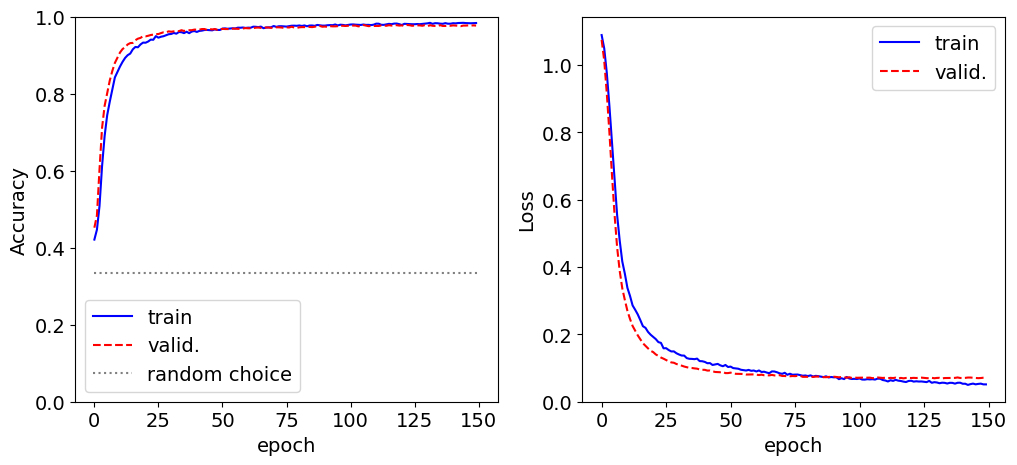

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


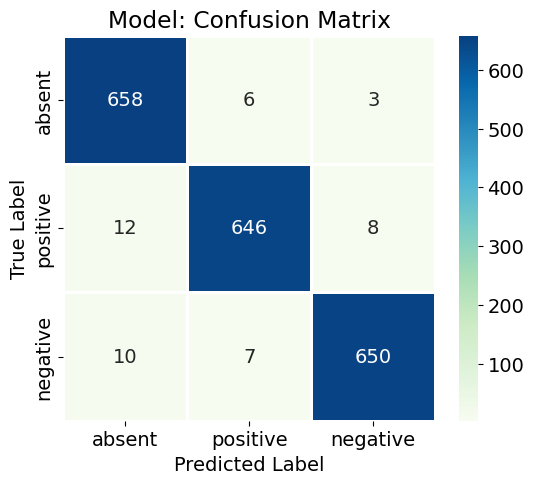

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LASSO (L1) Regularization with lambda = 1e-05


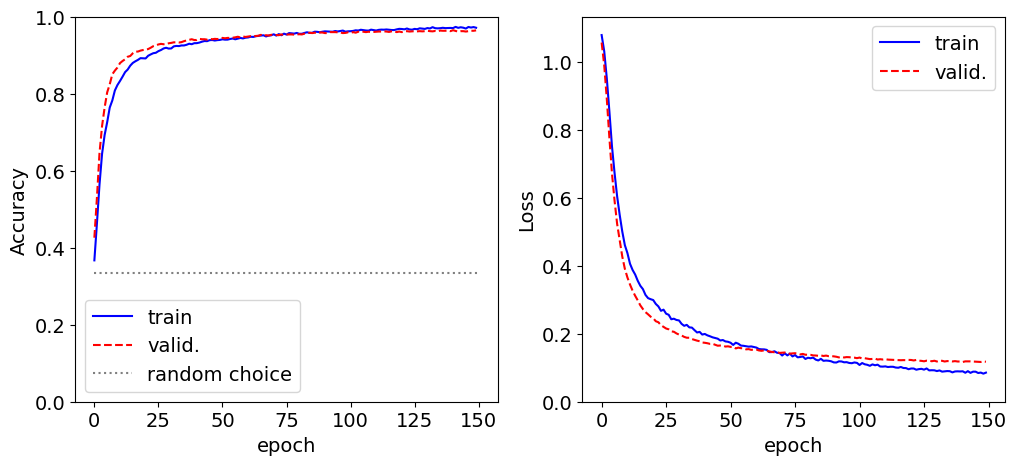

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


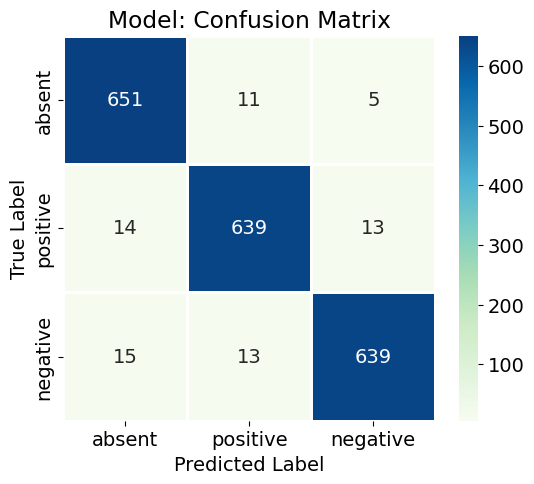

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LASSO (L1) Regularization with lambda = 0.0001


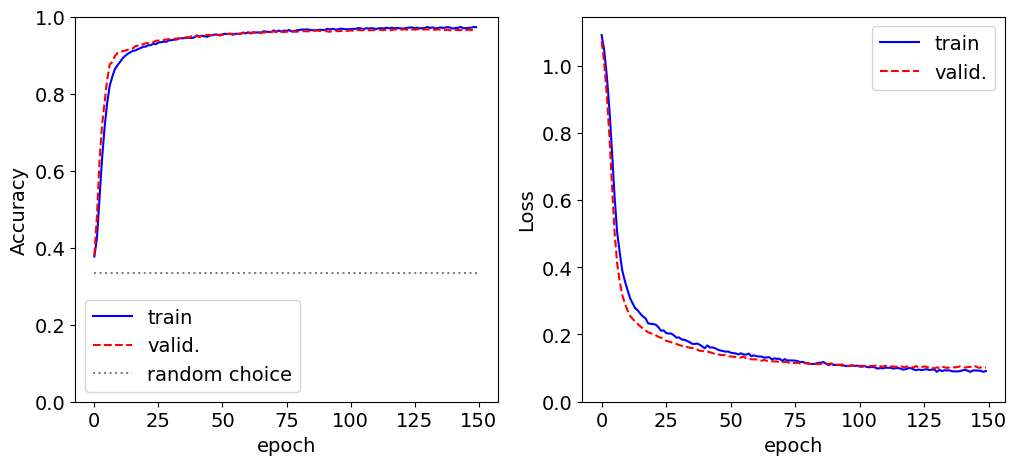

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


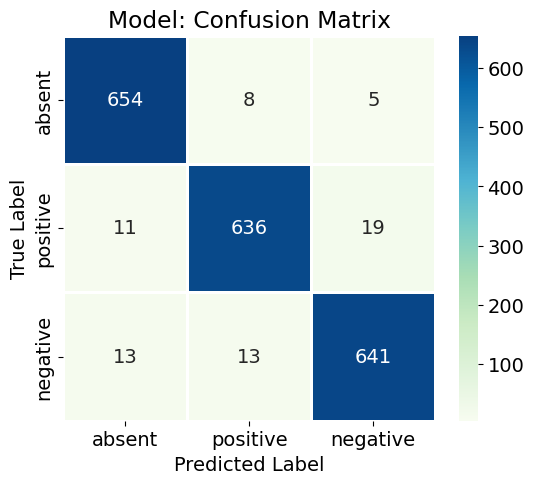

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LASSO (L1) Regularization with lambda = 0.001


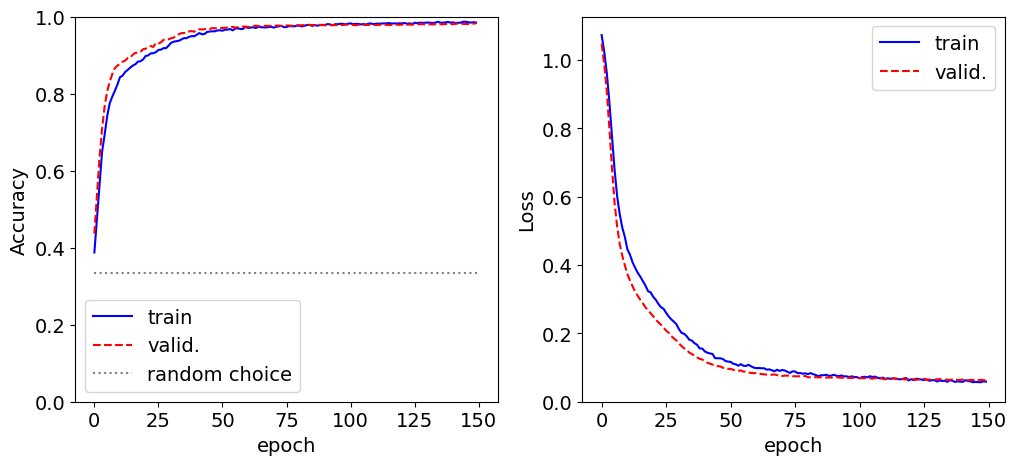

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


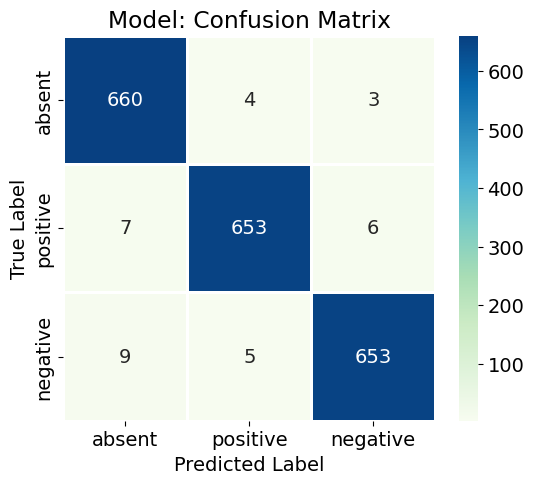

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LASSO (L1) Regularization with lambda = 0.01


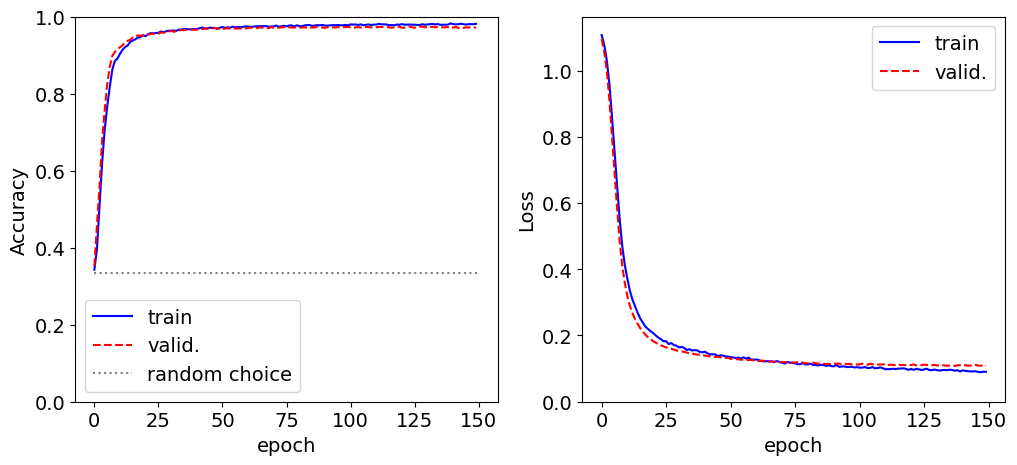

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


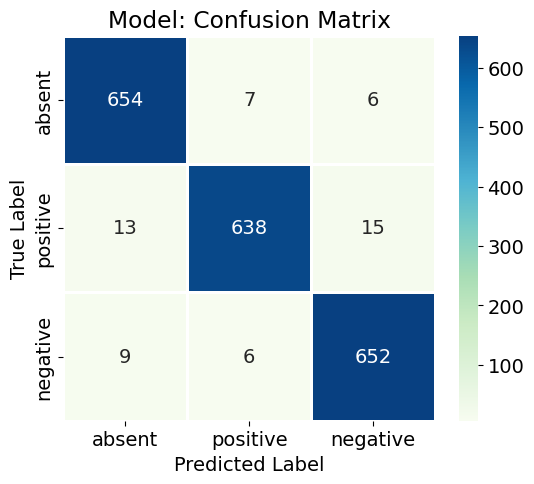

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LASSO (L1) Regularization with lambda = 0.1


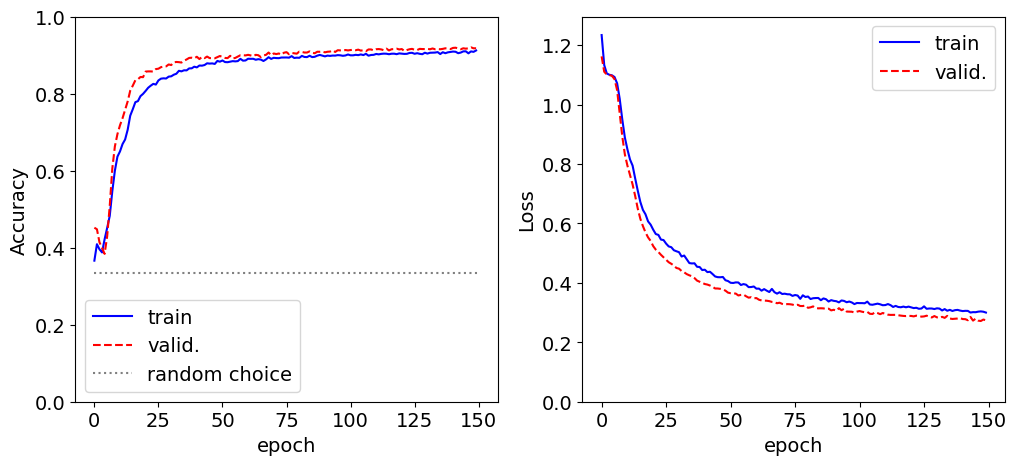

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


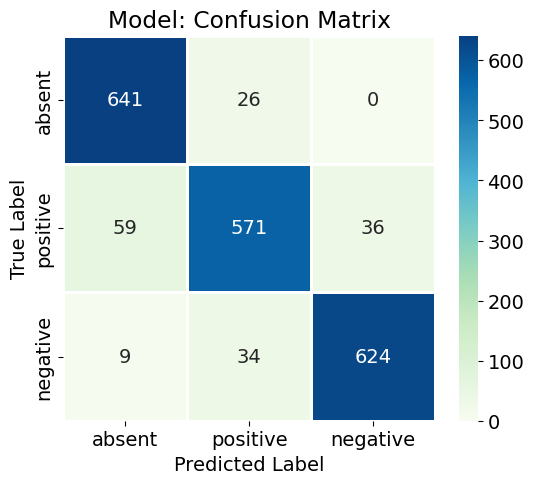

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LASSO (L1) Regularization with lambda = 1


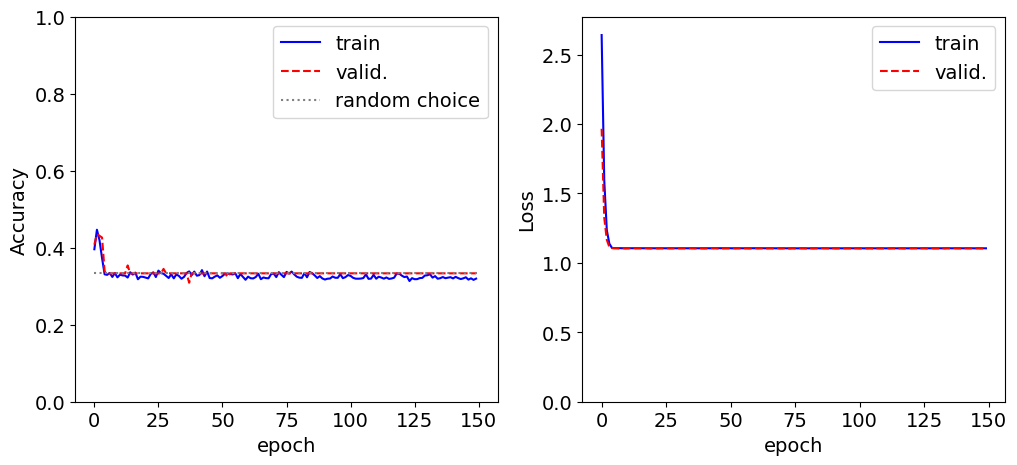

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


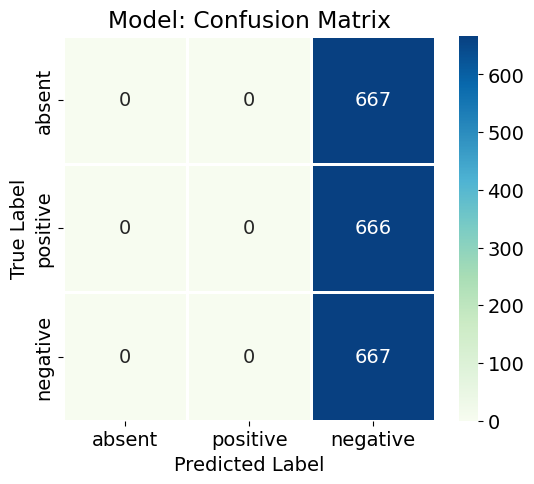

In [35]:
BATCH_SIZE = 200
EPOCHS = 150

for lambda_par in lambda_list:
    
    model = create_model_reg(lambda_par, 'LASSO', NCONV = 1)
    fit = model.fit(x_train,y_train,batch_size=BATCH_SIZE,
                    epochs=EPOCHS,
                    validation_data=(x_val, y_val),
                    verbose=0, shuffle=True) 
    print(f'LASSO (L1) Regularization with lambda = {lambda_par}')
    Show_history(fit)

    y_pred_val = model.predict(x_val)
    max_y_pred_val = np.argmax(y_pred_val, axis=1)
    max_y_val = np.argmax(y_val, axis=1)

    show_confusion_matrix(max_y_val, max_y_pred_val)

We observe that the predictions change slightly with λ regularization and worsen for higher λ values, indicating that the regularization becomes too restrictive.

### 3.2 Ridge Regularization (L2)

Here we train the model with Ridge regularization for each value of `lambda_par`.  
The LASSO penalty adds the following term to the loss:

$$
R_\theta = \displaystyle \sum_{i=1}^{N} \lvert \theta_i \rvert ^2
$$

where $ \theta_i $ are the model parameters.

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ridge (L2) Regularization with lambda = 0


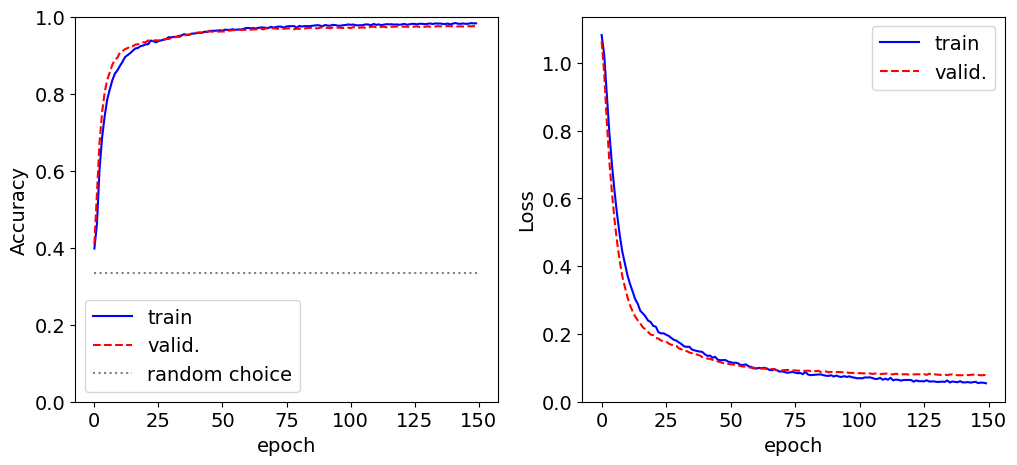

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


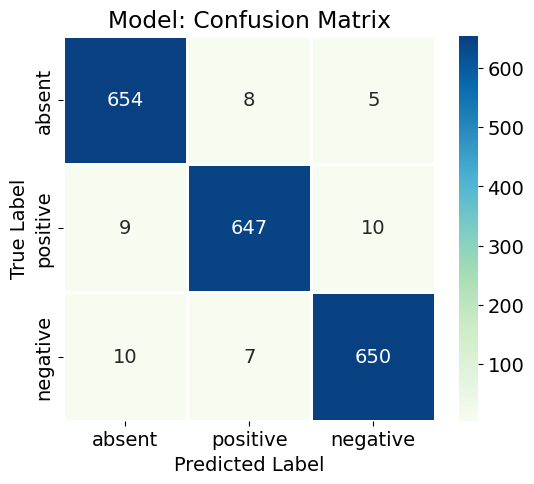

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ridge (L2) Regularization with lambda = 1e-05


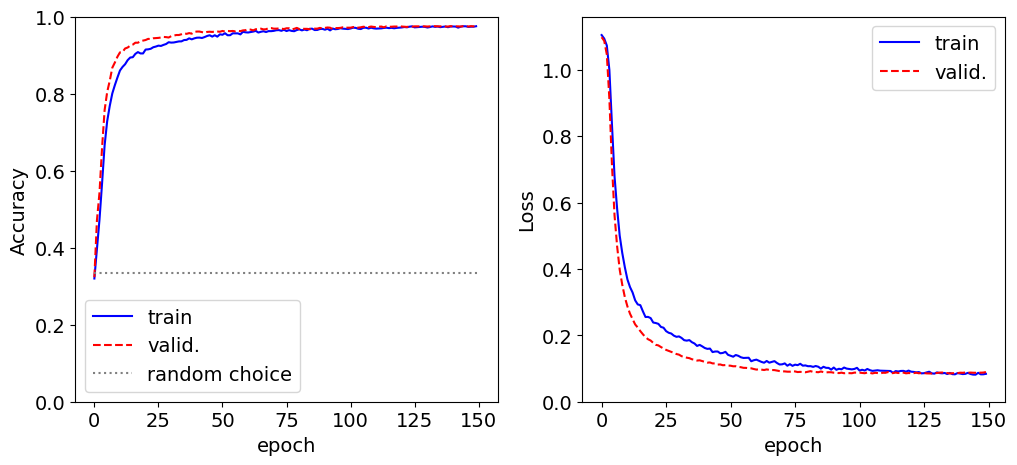

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


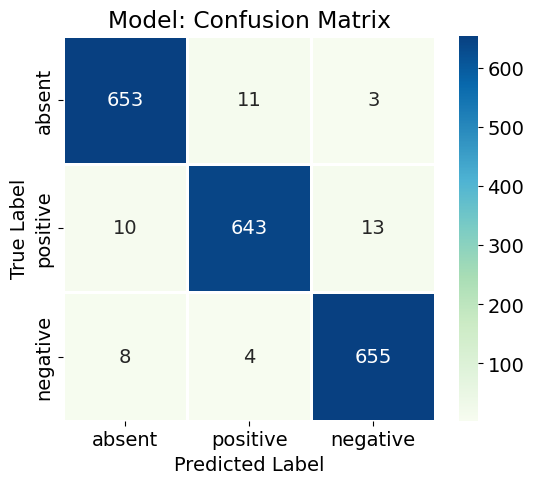

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ridge (L2) Regularization with lambda = 0.0001


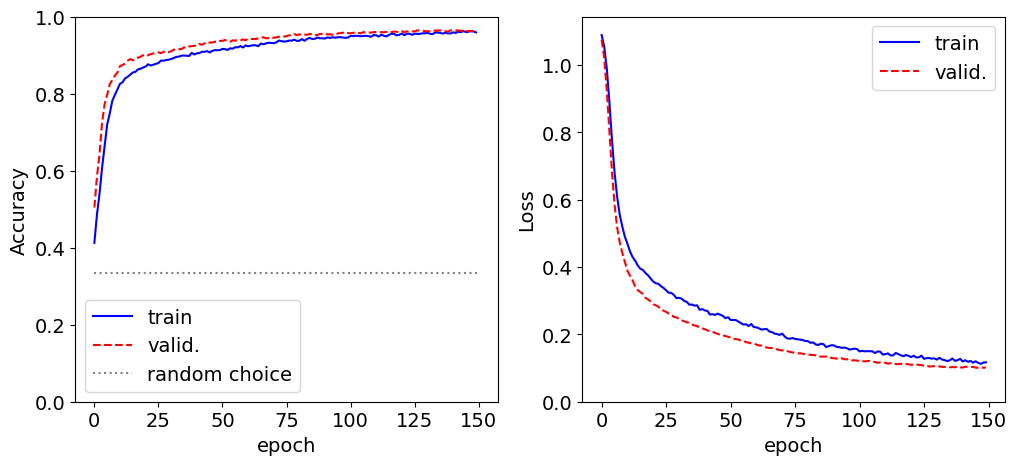

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


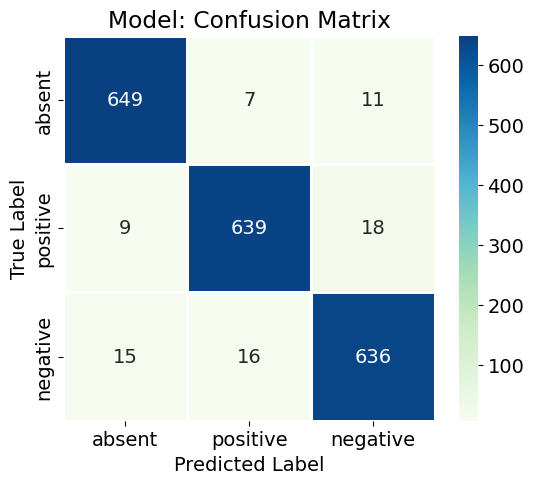

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ridge (L2) Regularization with lambda = 0.001


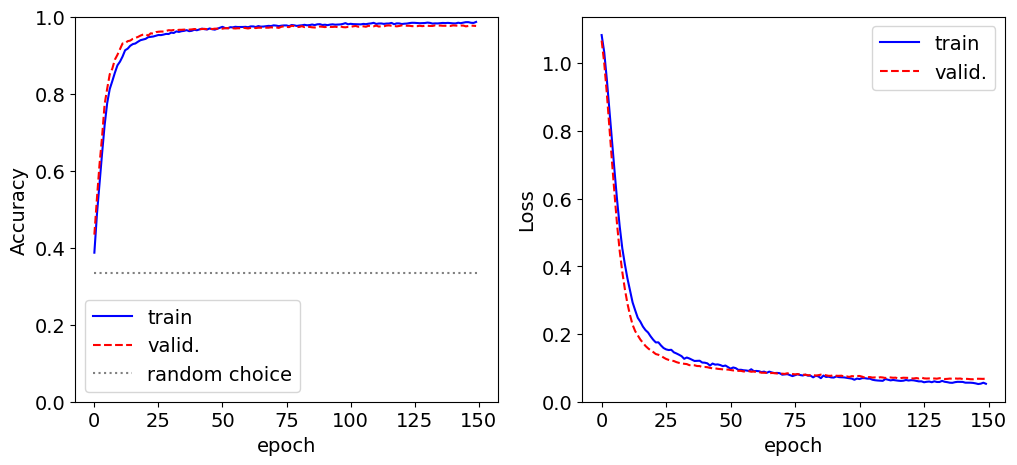

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


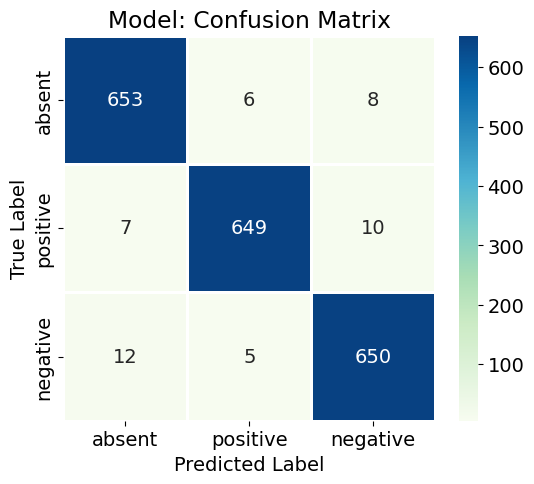

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ridge (L2) Regularization with lambda = 0.01


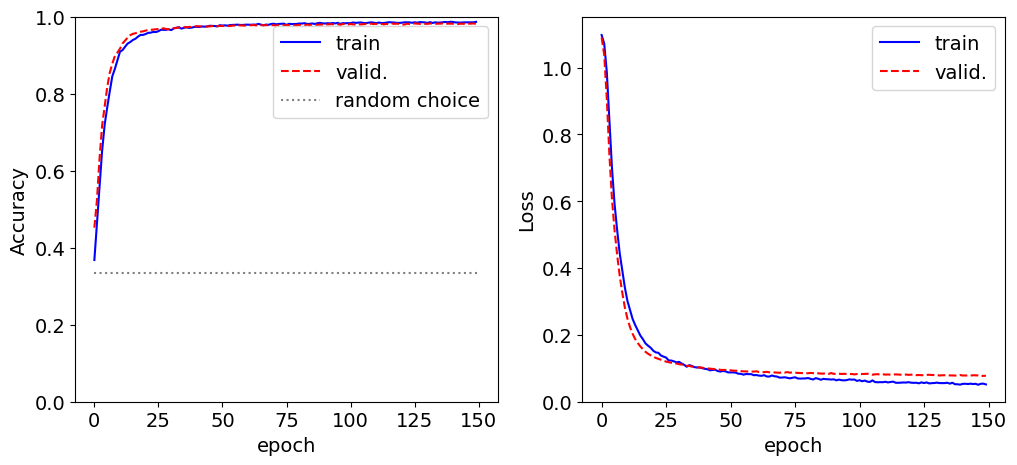

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


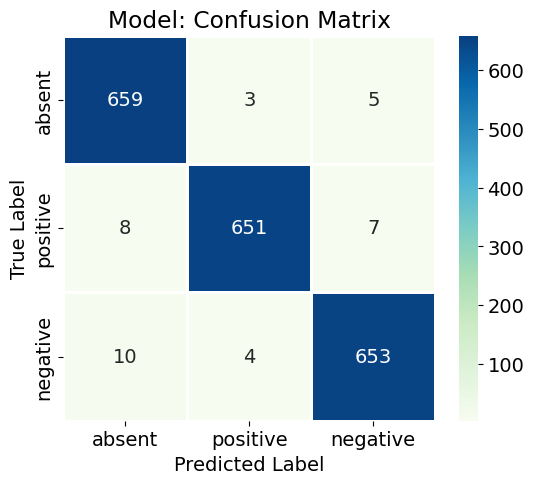

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ridge (L2) Regularization with lambda = 0.1


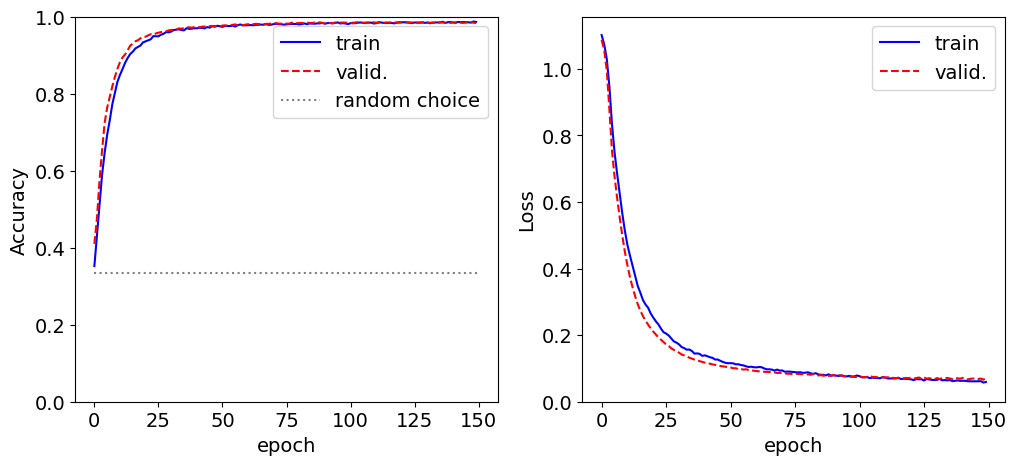

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


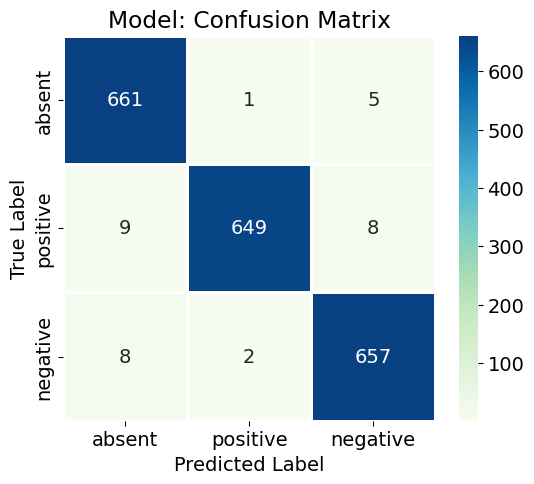

/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ridge (L2) Regularization with lambda = 1


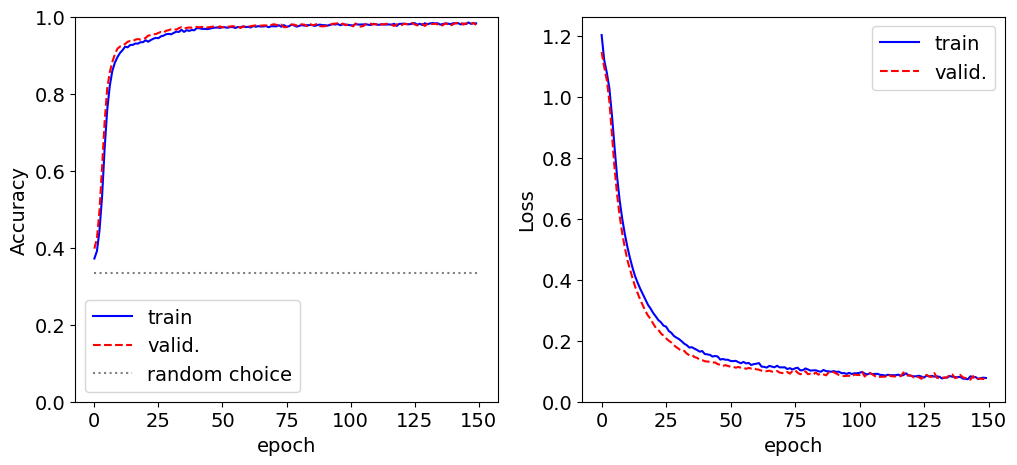

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


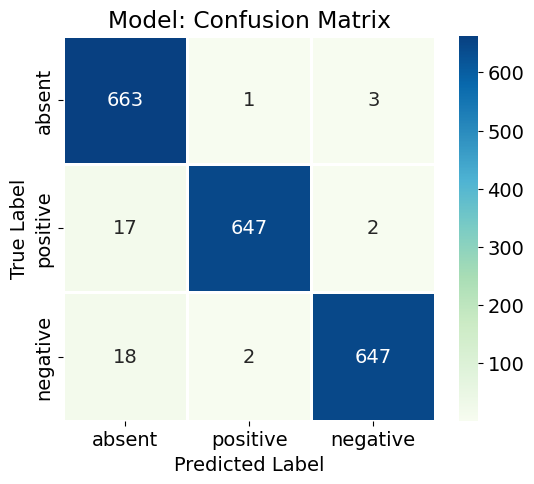

In [36]:
BATCH_SIZE = 200
EPOCHS = 150

for lambda_par in lambda_list:
    
    model = create_model_reg(lambda_par, 'Ridge', NCONV = 1)
    fit = model.fit(x_train,y_train,batch_size=BATCH_SIZE,
                    epochs=EPOCHS,
                    validation_data=(x_val, y_val),
                    verbose=0, shuffle=True) 
    print(f'Ridge (L2) Regularization with lambda = {lambda_par}')
    Show_history(fit)

    y_pred_val = model.predict(x_val)
    max_y_pred_val = np.argmax(y_pred_val, axis=1)
    max_y_val = np.argmax(y_val, axis=1)

    show_confusion_matrix(max_y_val, max_y_pred_val)

We observe that the predictions change slightly with λ regularization and worsen for higher λ values, indicating that the regularization becomes too restrictive.

### 3.3  Lambda optimization

Are performances of the CNN optimized at some intermediate value of lambda?

To find the best lambda for regularization we implement K-Fold Cross Validation.

In [18]:
def k_fold_cross_validation(x_train, y_train, reg_type, lambda_list, k: int, nepoch = 100, batch_size: int = 200):

    np.random.seed(123)
    best_perf = 1e20
    best_model = None
    best_hps = None

    # Fold idxs
    indices = np.arange(len(x_train))
    np.random.shuffle(indices)
    fold_size = len(x_train) // k

    x_folds = []
    y_folds = []
    for i in range(k):
        fold_idx = indices[i * fold_size: (i + 1) * fold_size]
        x_folds.append(x_train[fold_idx])
        y_folds.append(y_train[fold_idx])

    for lambda_par in lambda_list:
        model_perf = 0

        for test_idx in range(k):
            model = create_model_reg(lambda_par, reg_type, NCONV = 1)           
            # Training folds
            x_train_fold = np.concatenate([x for i, x in enumerate(x_folds) if i != test_idx])
            y_train_fold = np.concatenate([y for i, y in enumerate(y_folds) if i != test_idx])
            # Validation fold
            x_val_fold = x_folds[test_idx]
            y_val_fold = y_folds[test_idx]
            # fit and save the score
            fit = model.fit(x_train_fold, y_train_fold, validation_data=(x_val_fold, y_val_fold),
                            batch_size=batch_size, epochs=nepoch, verbose=0, shuffle=True) 
            model_perf += fit.history['val_loss'][-1]
        model_perf /= k

        if model_perf < best_perf:
            best_perf = model_perf
            best_lambda = lambda_par
            
    return best_lambda

In [14]:
best_lambda_lasso = k_fold_cross_validation(x_train, y_train, 'LASSO', lambda_list, k = 4, nepoch = 150, batch_size = 200)
print(f'Best Lambda found with K-Fold Cross Validation (LASSO):= {best_lambda_lasso}')

2026-03-19 10:45:16.523427: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Best Lambda found with K-Fold Cross Validation (LASSO):= 1e-05


In [17]:
best_lambda_ridge = k_fold_cross_validation(x_train, y_train, 'Ridge', lambda_list, k = 4, nepoch = 150, batch_size = 200)
print(f'Best Lambda found with K-Fold Cross Validation (Ridge):= {best_lambda_ridge}')

Best Lambda found with K-Fold Cross Validation (Ridge):= 0.001


Once the best lambda has been determined, we train the model using this value.

Epoch 1/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4130 - loss: 1.0841 - val_accuracy: 0.4865 - val_loss: 1.0597
Epoch 2/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5020 - loss: 1.0280 - val_accuracy: 0.5770 - val_loss: 0.9716
Epoch 3/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6004 - loss: 0.9211 - val_accuracy: 0.6765 - val_loss: 0.8337
Epoch 4/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6814 - loss: 0.7812 - val_accuracy: 0.7690 - val_loss: 0.6800
Epoch 5/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7377 - loss: 0.6580 - val_accuracy: 0.8090 - val_loss: 0.5594
Epoch 6/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7862 - loss: 0.5564 - val_accuracy: 0.8440 - val_loss: 0.4676
Epoch 7/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8096 - loss: 0.4836 - val_accuracy: 0.8675 - val_loss: 0.3934
Epoch 8/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8385 - loss: 0.4221 - val_accuracy: 0.8930 - 

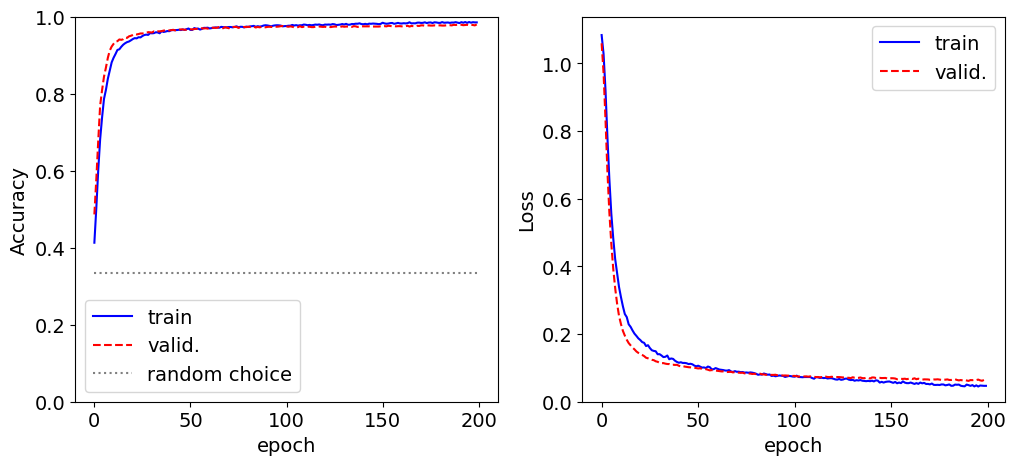

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


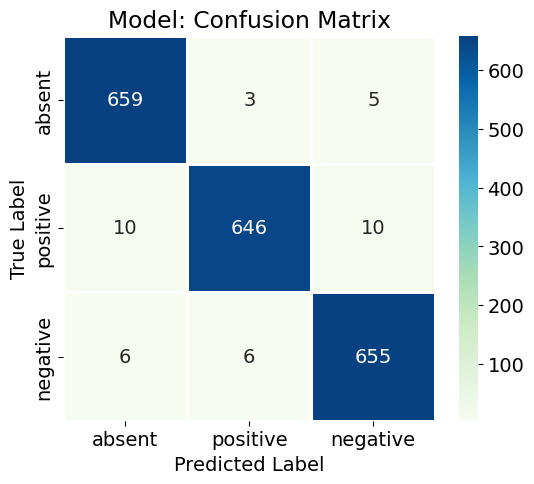

In [25]:
BATCH_SIZE = 200
EPOCHS = 200

best_model_lasso = create_model_reg(best_lambda_lasso, 'LASSO', NCONV = 1)
fit = best_model_lasso.fit(x_train,y_train,batch_size=BATCH_SIZE,
                epochs=EPOCHS,
                validation_data=(x_val, y_val),
                verbose=1, shuffle=True) 
print(f'Lasso (L1) Regularization with best validated lambda = {best_lambda_lasso}')
Show_history(fit)

y_pred_val = best_model_lasso.predict(x_val)
max_y_pred_val = np.argmax(y_pred_val, axis=1)
max_y_val = np.argmax(y_val, axis=1)

show_confusion_matrix(max_y_val, max_y_pred_val)

Epoch 1/200


/home/kevinbrugnera/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.3446 - loss: 1.1022 - val_accuracy: 0.3550 - val_loss: 1.0958
Epoch 2/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4117 - loss: 1.0898 - val_accuracy: 0.4410 - val_loss: 1.0810
Epoch 3/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4516 - loss: 1.0559 - val_accuracy: 0.4360 - val_loss: 1.0198
Epoch 4/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4835 - loss: 0.9755 - val_accuracy: 0.5700 - val_loss: 0.9161
Epoch 5/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6004 - loss: 0.8719 - val_accuracy: 0.7080 - val_loss: 0.7955
Epoch 6/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6949 - loss: 0.7588 - val_accuracy: 0.7805 - val_loss: 0.6716
Epoch 7/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7491 - loss: 0.6511 - val_accuracy: 0.8280 - val_loss: 0.5514
Epoch 8/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7930 - loss: 0.5535 - val_accuracy: 0.8535 - val_loss: 0

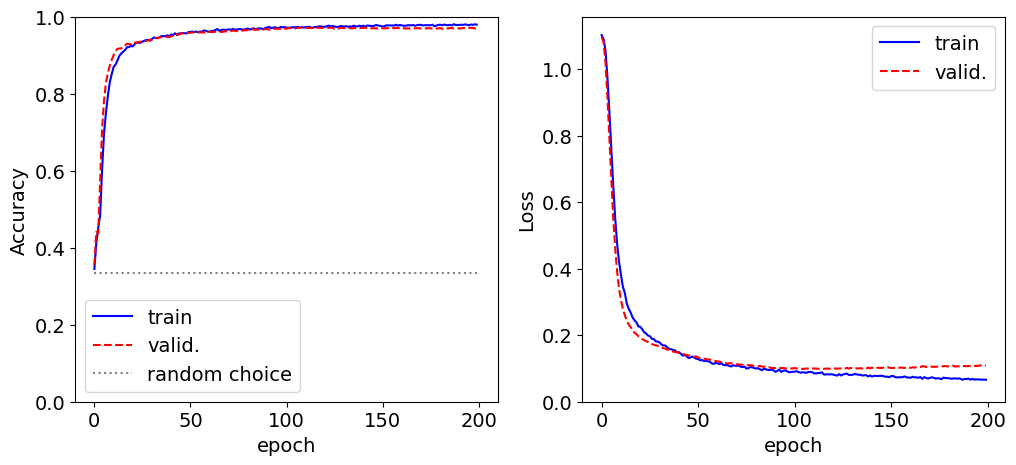

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


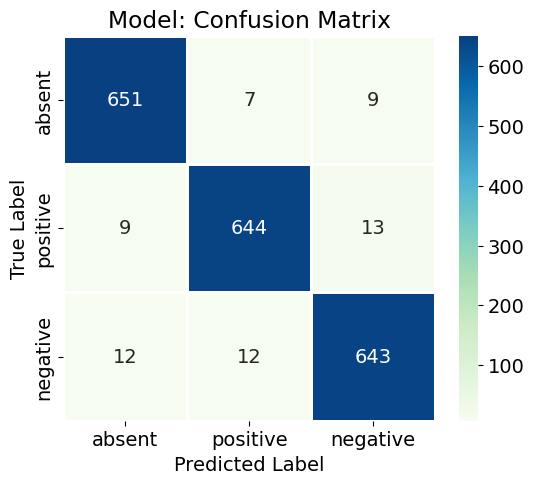

In [26]:
BATCH_SIZE = 200
EPOCHS = 200

best_model_ridge = create_model_reg(best_lambda_ridge, 'Ridge', NCONV = 1)
fit = best_model_ridge.fit(x_train,y_train,batch_size=BATCH_SIZE,
                epochs=EPOCHS,
                validation_data=(x_val, y_val),
                verbose=1, shuffle=True) 
print(f'Ridge (L2) Regularization with best validated lambda = {best_lambda_ridge}')
Show_history(fit)

y_pred_val = best_model_ridge.predict(x_val)
max_y_pred_val = np.argmax(y_pred_val, axis=1)
max_y_val = np.argmax(y_val, axis=1)

show_confusion_matrix(max_y_val, max_y_pred_val)

### 3.4 Improvements

Is there any improvement in the visualization and understanding of the weights in the filters? 

In [32]:
def Show_weights(model,l=0,label="model"):
    c=['r','y','c','b','m']
    m=['o','s','D','<','>']
    ms=10
    
    w = model.layers[l].get_weights()[0] # weights
    print(w.shape)
    wT=w.T
    print(wT.shape)
    M=len(wT)
    b = model.layers[l].get_weights()[1] # bias
    
    fig,AX=plt.subplots(1,2,figsize=(12,4.4))
    ax=AX[0]
    ax.axhline(0, c="k")
    ax.plot((0,))
    for i in range(M):
        ax.plot(wT[i][0],"-",c=c[i],marker=m[i],label=str(i),markersize=ms)
    ax.set_title(label+': filters of layer '+str(l))
    ax.set_xlabel('index')
    ax=AX[1]
    ax.axhline(0, c="k")
    for i in range(M):
        ax.plot((i),(b[i]),c=c[i],marker=m[i],label="filter "+str(i),markersize=ms)
    ax.set_title(label+': bias of layer '+str(l))
    ax.set_xlabel('filter nr')
    ax.set_xticks(np.arange(5))
    ax.legend()
    plt.show()

We show here the weights of the best model found through cross-validation in the LASSO regularization case.

(11, 1, 5)
(5, 1, 11)


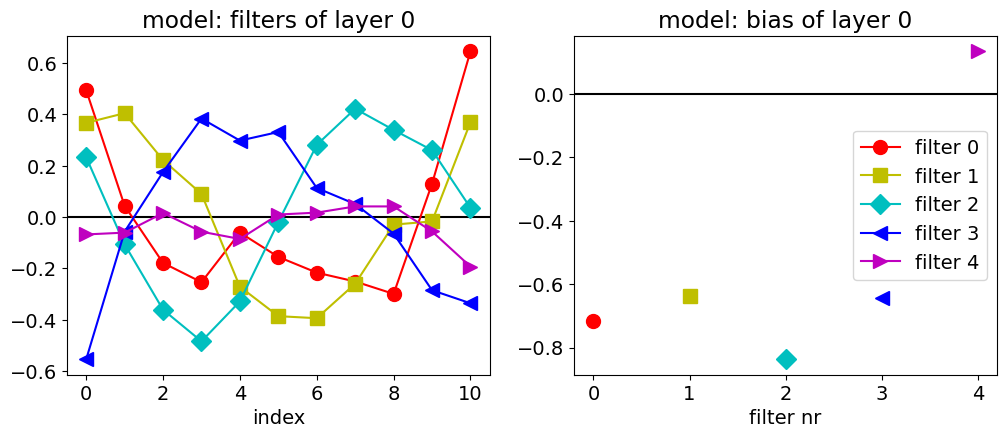

(7, 5, 5)
(5, 5, 7)


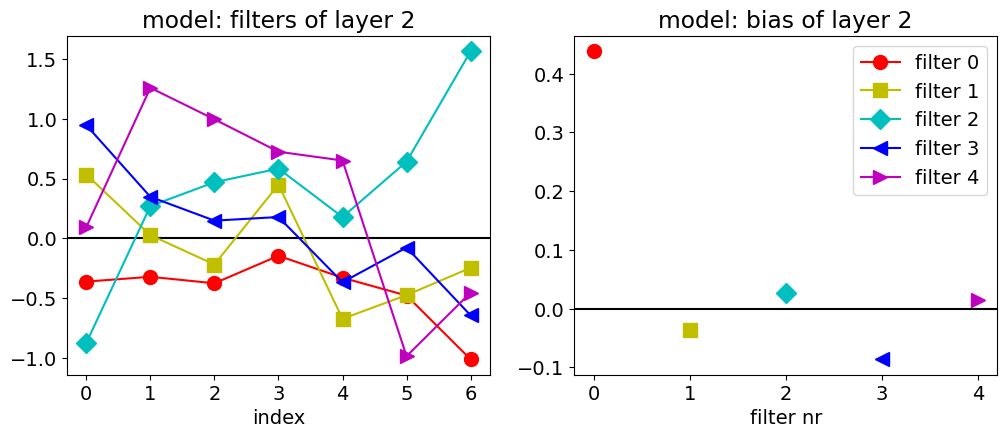

In [33]:
Show_weights(best_model_lasso, l=0, label="model")
Show_weights(best_model_lasso, l=2, label="model")

We show here the weights of the best model found through cross-validation in the RIDGE regularization case.

(11, 1, 5)
(5, 1, 11)


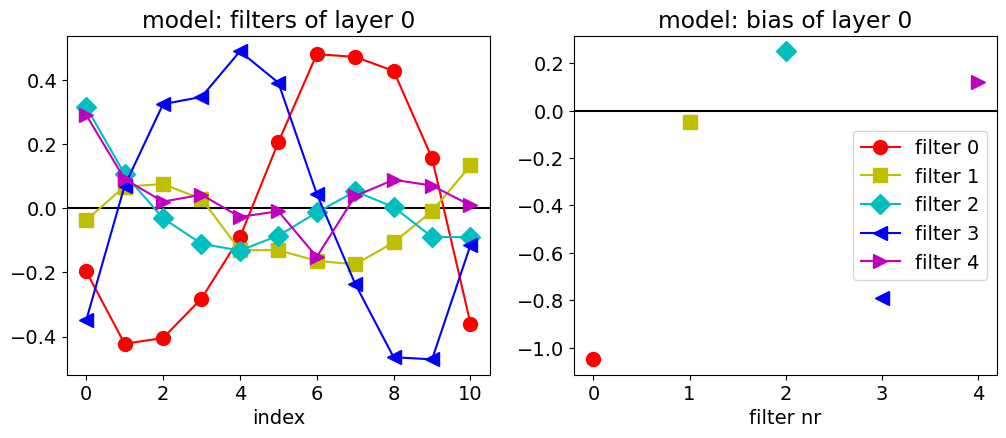

(7, 5, 5)
(5, 5, 7)


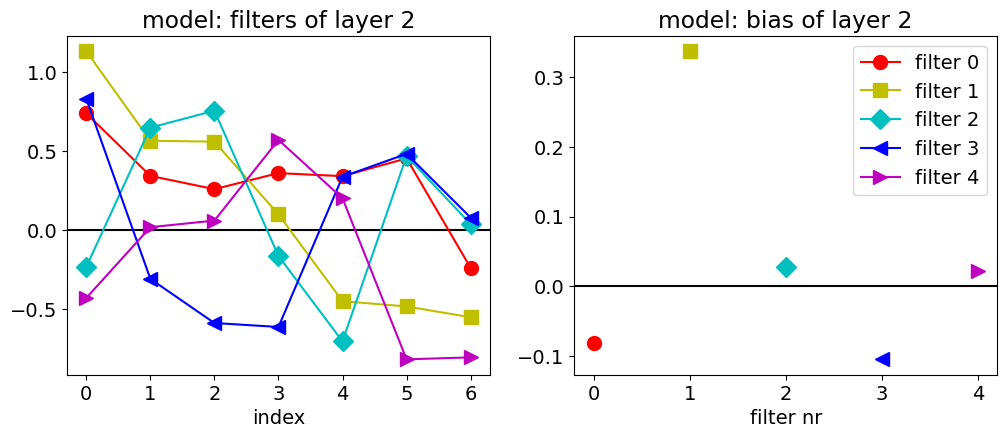

In [35]:
Show_weights(best_model_ridge, l=0, label="model")
Show_weights(best_model_ridge, l=2, label="model")